# Primera exploración de la base «Grupos de Proveedores — SECOP II»

**Archivo que se analiza:** `Grupos_de_Proveedores_-_SECOP_II_20260924.csv`

---

### Cómo usar este cuaderno

Ejecuta las celdas **en orden**, de arriba hacia abajo. En Jupyter o VS Code se ejecuta con `Shift + Enter`.

Cada bloque tiene dos partes: una explicación en lenguaje corriente y la celda de código que la ejecuta. Debajo de cada celda aparece el resultado.

**Antes de empezar**, el archivo CSV tiene que estar en la misma carpeta que este cuaderno.

### Lo que vamos a responder

1. Qué es esta base, qué contiene y cómo es cada columna
2. Medidas de tendencia central y distribución de cada variable
3. Mapa de calor de correlaciones
4. Nulos, ceros, faltantes y duplicados: la basura que hay que botar
5. Gráfico de dispersión cruzando dos variables importantes
6. Columnas tipo llave para conectar esta tabla con otras

## Paso 0 · Preparar las herramientas

Estas son las librerías que necesitamos. Si alguna falta, quita el `#` de la primera línea y ejecuta la celda una sola vez.

In [1]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Carga las librerías y fija el nombre del archivo y la fecha de corte.
# POR QUÉ    : pandas maneja tablas, numpy hace cuentas, matplotlib dibuja. La fecha de corte se define una sola vez para que todos los cálculos de antigüedad usen la misma.
# RESUELVE   : Deja el entorno listo y evita repetir el nombre del archivo en cada celda.
# ────────────────────────────────────────────────────────────────────

# !pip install pandas numpy matplotlib

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

%matplotlib inline
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

ARCHIVO = "Grupos_de_Proveedores_-_SECOP_II_20260924.csv"
CORTE   = pd.Timestamp("2026-09-24")   # fecha de descarga del archivo
print("Librerías cargadas.")

Librerías cargadas.


In [2]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Define la paleta de colores y una función que limpia el marco de las gráficas.
# POR QUÉ    : Si el estilo se define una vez aquí, todas las figuras del cuaderno salen iguales sin repetir código.
# RESUELVE   : Unifica el aspecto visual y quita el ruido de los ejes.
# ────────────────────────────────────────────────────────────────────

# ── Colores y estilo de todas las figuras ────────────────────────
INK, INK2, GRID, HUE, ACC = "#2B2723", "#6B635A", "#E4E0D9", "#1F6F8B", "#B4581F"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "figure.dpi": 110,
})
CMAP = LinearSegmentedColormap.from_list(
    "div", ["#1F6F8B", "#8FB3C2", "#EDEAE4", "#D8A583", "#B4581F"])

def limpiar_ejes(ax, eje_y=True):
    """Quita el marco de arriba y de la derecha y pone una rejilla suave."""
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    ax.grid(axis="y" if eje_y else "both", color=GRID, lw=.7)
    ax.set_axisbelow(True)
print("Estilo listo.")

Estilo listo.


## Paso 1 · Abrir el archivo y contar

Lo primero es lo más simple: cuántas filas y cuántas columnas hay.

Dos detalles del código que vale la pena entender:

- **`dtype=str`** le dice al programa que lea absolutamente todo como texto. Suena raro, pero es lo correcto: si lo dejamos decidir solo, convierte mal algunas columnas y se pierden datos en silencio.
- **`na_values=[""]`** indica que una celda en blanco significa «sin dato».

El archivo pesa cerca de 350 MB, así que esta celda puede tardar un par de minutos.

In [3]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Lee el archivo CSV y reporta su tamaño.
# POR QUÉ    : dtype=str obliga a leer TODO como texto. Suena innecesario, pero si dejamos que el programa adivine el tipo de cada columna, convierte mal algunas y los datos se pierden sin aviso. na_values indica que una celda en blanco es 'sin dato'.
# RESUELVE   : Trae los datos a memoria sin que el programa los altere por su cuenta.
# ────────────────────────────────────────────────────────────────────

df = pd.read_csv(ARCHIVO, dtype=str, keep_default_na=False, na_values=[""])

print(f"Filas    : {len(df):,}".replace(",", "."))
print(f"Columnas : {df.shape[1]}")
print(f"Memoria  : {df.memory_usage(deep=True).sum()/1e6:,.0f} MB".replace(",", "."))

Filas    : 707.750
Columnas : 33
Memoria  : 1.628 MB


Ahora miramos las primeras filas para hacernos una idea de qué hay adentro.

In [4]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Muestra las tres primeras filas.
# POR QUÉ    : Antes de calcular nada hay que ver con qué se está trabajando.
# RESUELVE   : Confirma que el archivo se leyó bien y deja ver el aspecto real de los datos.
# ────────────────────────────────────────────────────────────────────

df.head(3)

,Codigo grupo,Nombre Grupo,NIT Grupo,Es Entidad,Es proveedor,Esta activo,Fecha Creación Grupo,Codigo categoría principal grupo,Descripción código categoría principal grupo,Numero teléfono grupo,Numero fax grupo,Correo electronico grupo,Dirección grupo,Pais grupo,Departamento grupo,Minucipio grupo,Sitio web grupo,Tipo Empresa Grupo,Nombre representante legal grupo,Tipo doc representante legal grupo,Numero doc representante legal grupo,Telefono representante legal grupo,Correo representante legal grupo,Es Mipyme,Ubicación Grupo,Codigo participante,Nombre Participante,NIT Participante,Tipo Empresa Participante,Ubicación Participante,Fecha Creación Participante,Participacion,Es Lider del Grupo
0,707995049,UNIoN TEMPORAL VESTUARIO 2019,No Definido,No,No,Si,2019 Nov 09 12:00:00 AM,No Definido,No Definido,No Provisto,No Provisto,No Provisto,No Provisto,CO,No Provisto,No Provisto,No Provisto,UNIoN TEMPORAL,CARLOS ALBERTO DIAZ ROZO,No Definido,No Definido,3102221433,nubia.a@jobwear.net,NO,No definido,700354020,COLOMBIANA DE TEXTILES POR MAYOR S.A,860045541,SOCIEDAD ANoNIMA ABIERTA COLOMBIANA,CO,2015 Oct 07 12:00:00 AM,60,Verdadero
1,735670200,CONSORCIO ALCA 013,10261629,No,No,Si,2026 Feb 23 12:00:00 AM,No Definido,No Definido,6063726595,No Provisto,INGELUIS63@HOTMAIL.COM,CL 22 # 22 - 26 OF 609,CO,No Provisto,MANIZALES,No Provisto,CONSORCIO,LUIS ALBERTO CARVAJAL ZULUAGA,Cédula de Ciudadanía,10261629,3136443611,ingeluis63@hotmail.com,SI,CO-CAL-17001,707179602,LUIS ALBERTO CARVAJAL ZULUAGA,10261629,PERSONA NATURAL COLOMBIANA,No definido,2019 May 31 12:00:00 AM,50,Verdadero
2,721224129,CONSORCIO VIAL EL DORADO,901702222,No,No,Si,2023 Mar 13 12:00:00 AM,No Definido,No Definido,3215399203,No Provisto,CONSORCIOVIASDORADO@GMAIL.COM,CALLE 46 4 104 - BARRIo CENTRO,CO,No Provisto,MONTERiA,No Provisto,CONSORCIO,JOSE ALFREDO HERNANDEZ FURNIELES,NIT,901702222,3215399203,jhernandezfurnieles@gmail.com,SI,CO-COR-23001,719208399,CONSTRUCCIONES HHT S.A.S,900767893,OTRO,CO-BOL-13001,2022 Sep 16 12:00:00 AM,10,Falso


## Paso 2 · Qué representa una fila

Esta es la parte que más se presta a confusión y conviene resolverla de entrada.

La idea es comparar cuántas filas hay contra cuántos códigos de grupo distintos hay. Si los dos números fueran iguales, cada fila sería un grupo. Si hay menos códigos que filas, entonces un mismo grupo ocupa varias filas.

In [5]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Compara cuántas filas hay contra cuántos grupos distintos.
# POR QUÉ    : Si los dos números fueran iguales, cada fila sería un grupo. Si hay menos grupos que filas, un mismo grupo ocupa varias filas.
# RESUELVE   : Responde la pregunta más importante del análisis: qué representa una fila.
# ────────────────────────────────────────────────────────────────────

print(f"Filas totales           : {len(df):,}".replace(",", "."))
print(f"Códigos de grupo únicos : {df['Codigo grupo'].nunique():,}".replace(",", "."))
print(f"Filas por grupo (prom.) : {len(df)/df['Codigo grupo'].nunique():.2f}")

Filas totales           : 707.750
Códigos de grupo únicos : 319.523
Filas por grupo (prom.) : 2.22


**Conclusión:** hay más filas que grupos, así que:

> **Una fila = un socio dentro de un grupo.**
> Si un consorcio tiene tres empresas, ese consorcio ocupa tres filas.

Por eso las primeras 25 columnas (las que describen al grupo) se repiten idénticas en todas las filas del mismo grupo, y solo cambian las últimas 8, que describen al socio.

En vocabulario de bases de datos esto se llama **tabla en formato largo**: la información del «padre» (el grupo) se repite en cada «hijo» (el socio).

**Ojo con esto:** contar filas no es contar consorcios.

## Punto 1 · Descripción de las variables

### 1.1 Qué es esta base y para qué sirve

- **Nombre oficial:** Grupos de Proveedores — SECOP II
- **Identificador:** `ceth-n4bn` · https://www.datos.gov.co/d/ceth-n4bn
- **Quién la publica:** Agencia Nacional de Contratación Pública — Colombia Compra Eficiente
- **Descripción oficial:** *«Registra la información de las uniones temporales o grupos creados por proveedores para postularse en conjunto a procesos de compra pública»*

**El propósito de fondo.** En Colombia, cuando una empresa sola no cumple los requisitos de una licitación —porque le falta experiencia, capacidad financiera o una especialidad— se puede unir con otras y presentarse en conjunto. Esa unión se llama **consorcio** o **unión temporal**, y tiene que quedar registrada con el porcentaje que le corresponde a cada socio.

Entonces esta base **deja constancia pública de quién se asocia con quién para venderle al Estado, y en qué proporción**.

Eso la vuelve útil para tres cosas distintas:

1. **Para una empresa que quiere licitar:** ver con quién se están aliando sus competidores.
2. **Para un auditor:** detectar empresas que siempre aparecen juntas, lo que puede indicar acuerdos entre competidores.
3. **Para un estudio de mercado:** medir qué tan concentrada está la contratación pública.

### 1.2 Las columnas, una por una

La siguiente celda arma la tabla de descripción: nombre visible, nombre del campo en la API, tipo de dato, cuántos valores llenos tiene y cuántos valores distintos.

In [6]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Arma la tabla-diccionario de las 33 columnas.
# POR QUÉ    : El nombre visible de la columna no dice ni el tipo de dato ni para qué sirve. El diccionario API trae esa información del catálogo oficial, y se le suma el conteo real de valores llenos y distintos que sale del archivo.
# RESUELVE   : Entrega el punto 1 del ejercicio en una sola tabla.
# ────────────────────────────────────────────────────────────────────

# Nombre del campo en la API y tipo declarado, tomados del catálogo oficial
API = {
 "Codigo grupo":"codigo_grupo|texto|Código del grupo en la plataforma",
 "Nombre Grupo":"nombre_grupo|texto|Nombre del consorcio o unión temporal",
 "NIT Grupo":"nit_grupo|texto|NIT del grupo conformado",
 "Es Entidad":"es_entidad|texto|Si está registrado como entidad estatal",
 "Es proveedor":"es_proveedor|texto|Si está registrado como proveedor",
 "Esta activo":"esta_activo|texto|Si el grupo sigue vigente",
 "Fecha Creación Grupo":"fecha_creaci_n_grupo|fecha|Cuándo se creó el grupo",
 "Codigo categoría principal grupo":"codigo_categor_a_principal_grupo|texto|Código del bien o servicio principal",
 "Descripción código categoría principal grupo":"descripci_n_c_digo_categor_a_principal_grupo|texto|Nombre de esa categoría",
 "Numero teléfono grupo":"numero_tel_fono_grupo|texto|Teléfono del grupo",
 "Numero fax grupo":"numero_fax|texto|Fax del grupo",
 "Correo electronico grupo":"correo_electronico_grupo|texto|Correo del grupo",
 "Dirección grupo":"direcci_n_grupo|texto|Dirección física",
 "Pais grupo":"pais_grupo|texto|País",
 "Departamento grupo":"departamento_grupo|texto|Departamento",
 "Minucipio grupo":"minucipio|texto|Municipio (el nombre viene mal escrito en la fuente)",
 "Sitio web grupo":"sitio_web_grupo|texto|Página web",
 "Tipo Empresa Grupo":"tipo_empresa_grupo|texto|Consorcio, unión temporal, etc.",
 "Nombre representante legal grupo":"nombre_representante_legal_grupo|texto|Quién firma por el grupo",
 "Tipo doc representante legal grupo":"tipo_doc_representante_legal_grupo|texto|Cédula, pasaporte, etc.",
 "Numero doc representante legal grupo":"numero_doc_representante_legal_grupo|texto|Número del documento",
 "Telefono representante legal grupo":"telefono_representante_legal_grupo|texto|Teléfono del representante",
 "Correo representante legal grupo":"correo_representante_legal_grupo|texto|Correo del representante",
 "Es Mipyme":"es_mipyme|texto|Si el grupo se declara micro, pequeña o mediana",
 "Ubicación Grupo":"ubicaci_n_grupo|texto|Código de ubicación geográfica",
 "Codigo participante":"codigo_participante|texto|Código del socio en la plataforma",
 "Nombre Participante":"nombre_participante|texto|Razón social del socio",
 "NIT Participante":"nit_participante|texto|NIT del socio",
 "Tipo Empresa Participante":"tipo_empresa_participante|texto|S.A.S., persona natural, etc.",
 "Ubicación Participante":"ubicaci_n_participante|texto|Ubicación del socio",
 "Fecha Creación Participante":"fecha_creaci_n_participante|fecha|Cuándo se registró el socio",
 "Participacion":"participacion|NÚMERO|Porcentaje que le corresponde al socio",
 "Es Lider del Grupo":"es_lider_del_grupo|texto|Si ese socio lidera el grupo",
}

filas = []
for i, col in enumerate(df.columns, 1):
    campo, tipo, desc = API.get(col, "?|?|?").split("|")
    filas.append({"#": i, "Nombre visible": col, "Campo API": campo,
                  "Tipo": tipo, "Qué guarda": desc,
                  "Llenos": df[col].notna().sum(),
                  "Únicos": df[col].nunique(dropna=True)})

diccionario = pd.DataFrame(filas)
diccionario

,#,Nombre visible,Campo API,Tipo,Qué guarda,Llenos,Únicos
0,1,Codigo grupo,codigo_grupo,texto,Código del grupo en la plataforma,707750,319523
1,2,Nombre Grupo,nombre_grupo,texto,Nombre del consorcio o unión temporal,707750,275178
2,3,NIT Grupo,nit_grupo,texto,NIT del grupo conformado,707266,32041
3,4,Es Entidad,es_entidad,texto,Si está registrado como entidad estatal,707750,2
4,5,Es proveedor,es_proveedor,texto,Si está registrado como proveedor,707750,2
5,6,Esta activo,esta_activo,texto,Si el grupo sigue vigente,707750,2
6,7,Fecha Creación Grupo,fecha_creaci_n_grupo,fecha,Cuándo se creó el grupo,707750,3634
7,8,Codigo categoría principal grupo,codigo_categor_a_principal_grupo,texto,Código del bien o servicio principal,707750,69
8,9,Descripción código categoría principal grupo,descripci_n_c_digo_categor_a_principal_grupo,texto,Nombre de esa categoría,707750,68
9,10,Numero teléfono grupo,numero_tel_fono_grupo,texto,Teléfono del grupo,707387,24047


### 1.3 El hallazgo incómodo

Mira la columna **Tipo** de la tabla de arriba: de 33 columnas, **32 son texto y solo 1 es número** (`Participacion`). Las dos fechas van aparte, porque una fecha no es ni texto ni número.

Esto es un problema práctico. El ejercicio pide medidas de tendencia central y un mapa de correlaciones, y las dos cosas necesitan números. Con una sola columna numérica no hay nada que correlacionar.

**La solución es fabricar variables numéricas nuevas a partir de las que ya están.** Eso se llama *derivar variables* y es normal y esperado en cualquier análisis. Lo hacemos en el paso siguiente.

## Paso 3 · Limpieza

### 3.1 Los vacíos disfrazados

Aquí aparece la primera trampa seria de esta base.

Casi no hay celdas realmente vacías. Lo que hay son celdas con textos que *significan* vacío: `"No Definido"`, `"No Provisto"`, `"No definido"` con minúscula. Para el computador eso es texto válido, así que si le preguntamos «¿cuántos datos faltan?» responde «casi ninguno».

A esos valores se les llama **centinelas**, y hay que traducirlos a vacío antes de medir cualquier cosa.

In [7]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Traduce a vacío los textos que significan vacío.
# POR QUÉ    : La base casi no tiene celdas en blanco. Lo que tiene son textos como 'No Definido' que el programa lee como dato válido. A esos valores se les llama centinelas.
# RESUELVE   : Sin este paso, cualquier conteo de datos faltantes da mal.
# ────────────────────────────────────────────────────────────────────

CENTINELAS = {"No Definido", "No definido", "NO DEFINIDO", "No Provisto",
              "No provisto", "NO PROVISTO", "No Aplica", "N/A", "NA",
              "SIN DATO", "-", "."}

antes = df.notna().sum().sum()
for col in df.columns:
    df[col] = df[col].where(~df[col].isin(CENTINELAS), np.nan)
despues = df.notna().sum().sum()

print(f"Celdas que parecían llenas y en realidad estaban vacías: "
      f"{antes - despues:,}".replace(",", "."))

Celdas que parecían llenas y en realidad estaban vacías: 6.653.646


### 3.2 Los números escritos con coma

Segunda trampa. La columna `Participacion` está declarada como número en el catálogo, pero muchos valores vienen escritos como `"33,33"` con coma decimal. Para el computador eso es texto, no un número.

Primero veamos el tamaño del problema.

In [8]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Mide cuántos valores de Participacion el programa rechaza y por qué.
# POR QUÉ    : errors='coerce' convierte a vacío todo lo que no logre leer como número. Comparando ese resultado contra los vacíos reales se separan dos problemas distintos: los que no tienen dato y los que están mal escritos.
# RESUELVE   : Cuantifica el problema antes de arreglarlo, para saber cuánto está en juego.
# ────────────────────────────────────────────────────────────────────

crudo = pd.to_numeric(df["Participacion"], errors="coerce")
print(f"Valores que SÍ se convierten de una vez : {crudo.notna().sum():,}".replace(",", "."))
print(f"Valores que el programa rechaza         : {crudo.isna().sum():,}".replace(",", "."))
print(f"   de esos, realmente vacíos            : {df['Participacion'].isna().sum():,}".replace(",", "."))
print(f"   de esos, escritos con coma decimal   : "
      f"{(crudo.isna() & df['Participacion'].notna()).sum():,}".replace(",", "."))
print("\nEjemplos de los que traen coma:")
print(df.loc[crudo.isna() & df["Participacion"].notna(), "Participacion"]
        .value_counts().head(6).to_string())

Valores que SÍ se convierten de una vez : 690.160
Valores que el programa rechaza         : 17.590
   de esos. realmente vacíos            : 9.113
   de esos. escritos con coma decimal   : 8.477

Ejemplos de los que traen coma:
Participacion
33,33    1053
47,5      584
33,34     515
37,5      379
0,5       279
33,3      237


Ahora los arreglamos: cambiamos la coma por punto y volvemos a convertir. Ese solo cambio recupera miles de registros que de otro modo se perderían sin que nadie se diera cuenta.

In [9]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Cambia la coma por punto y convierte la columna a número.
# POR QUÉ    : En Colombia se escribe 33,33 con coma decimal. El computador espera 33.33 con punto. Ese solo carácter hace que miles de valores se pierdan en silencio.
# RESUELVE   : Recupera todos los registros que el paso anterior mostró como rechazados.
# ────────────────────────────────────────────────────────────────────

df["participacion_pct"] = pd.to_numeric(
    df["Participacion"].astype(str).str.replace(",", ".", regex=False),
    errors="coerce")

print(f"Valores recuperados tras el arreglo: {df['participacion_pct'].notna().sum():,}"
      .replace(",", "."))

Valores recuperados tras el arreglo: 698.637


### 3.3 Las fechas

Las fechas vienen en un formato poco común: `2019 Nov 09 12:00:00 AM`. Hay que decirle al programa exactamente cómo leerlo.

In [10]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Convierte las dos columnas de fecha a fechas de verdad.
# POR QUÉ    : Las fechas vienen como '2019 Nov 09 12:00:00 AM', un formato poco común que hay que declarar explícitamente con el código FMT.
# RESUELVE   : Habilita las restas entre fechas, que son la base de las variables de antigüedad.
# ────────────────────────────────────────────────────────────────────

FMT = "%Y %b %d %I:%M:%S %p"
df["f_grupo"] = pd.to_datetime(df["Fecha Creación Grupo"], format=FMT, errors="coerce")
df["f_socio"] = pd.to_datetime(df["Fecha Creación Participante"], format=FMT, errors="coerce")

print(f"Fechas de grupo leídas : {df['f_grupo'].notna().sum():,}".replace(",", "."))
print(f"Fechas de socio leídas : {df['f_socio'].notna().sum():,}".replace(",", "."))
print(f"Rango de grupos : {df['f_grupo'].min().date()}  ->  {df['f_grupo'].max().date()}")
print(f"Rango de socios : {df['f_socio'].min().date()}  ->  {df['f_socio'].max().date()}")

Fechas de grupo leídas : 707.750
Fechas de socio leídas : 698.636
Rango de grupos : 2015-06-10  ->  2026-09-24
Rango de socios : 2015-02-14  ->  2026-09-24


### 3.4 Fabricar las variables numéricas

Estas son las siete variables que vamos a analizar. Todas salen de lo que ya está en la tabla.

| Variable | Cómo se construye | Qué mide |
|---|---|---|
| `participacion_pct` | La columna limpia | El porcentaje del socio |
| `n_socios` | Cuántas filas tiene cada código de grupo | Cuántas empresas componen el grupo |
| `suma_participacion` | Suma de los porcentajes del grupo | Sirve para verificar que den 100 |
| `n_grupos_del_socio` | En cuántos grupos aparece cada NIT | Qué tan activo es ese socio |
| `antiguedad_grupo_dias` | Días entre la creación del grupo y hoy | Qué tan viejo es el grupo |
| `antiguedad_socio_dias` | Días entre el registro del socio y hoy | Qué tan veterano es el socio |
| `dif_dias_socio_grupo` | Días entre que el socio se registró y nació el grupo | Cuánto esperó antes de asociarse |

In [11]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Construye las siete variables numéricas derivadas.
# POR QUÉ    : La base tiene una sola columna numérica, y el ejercicio pide estadísticos y correlaciones. groupby agrupa las filas por grupo y transform devuelve el resultado repetido en cada fila, que es lo que permite mezclar el dato del grupo con el dato del socio.
# RESUELVE   : Crea la materia prima de los puntos 2, 3 y 5.
# ────────────────────────────────────────────────────────────────────

g = df.groupby("Codigo grupo")
df["n_socios"]              = g["Codigo grupo"].transform("size")
df["suma_participacion"]    = g["participacion_pct"].transform("sum")
df["n_grupos_del_socio"]    = df.groupby("NIT Participante")["Codigo grupo"].transform("nunique")
df["antiguedad_grupo_dias"] = (CORTE - df["f_grupo"]).dt.days
df["antiguedad_socio_dias"] = (CORTE - df["f_socio"]).dt.days
df["dif_dias_socio_grupo"]  = (df["f_grupo"] - df["f_socio"]).dt.days

NUM = ["participacion_pct", "n_socios", "suma_participacion", "n_grupos_del_socio",
       "antiguedad_grupo_dias", "antiguedad_socio_dias", "dif_dias_socio_grupo"]
ETQ = {"participacion_pct":"Participación (%)", "n_socios":"Socios por grupo",
       "suma_participacion":"Suma de participación", "n_grupos_del_socio":"Grupos por socio",
       "antiguedad_grupo_dias":"Antigüedad grupo (días)",
       "antiguedad_socio_dias":"Antigüedad socio (días)",
       "dif_dias_socio_grupo":"Días socio → grupo"}

print("Variables numéricas construidas:")
for v in NUM:
    print(f"   · {v}")

Variables numéricas construidas:
   · participacion_pct
   · n_socios
   · suma_participacion
   · n_grupos_del_socio
   · antiguedad_grupo_dias
   · antiguedad_socio_dias
   · dif_dias_socio_grupo


## Punto 2 · Medidas de tendencia central y distribución

Tres palabras que hay que tener claras antes de leer la tabla:

- **Media (promedio):** sumar todo y dividir. Se desvía cuando hay valores extremos.
- **Mediana:** el valor que queda justo en la mitad al ordenar todos los datos. Los extremos no la mueven.
- **Desviación estándar:** qué tan regados están los datos alrededor del promedio.
- **Asimetría:** si la distribución está corrida hacia un lado. Cerca de cero es simétrica.

**La regla de oro:** cuando la media y la mediana se parecen, los datos están repartidos de forma pareja. Cuando se separan mucho, hay valores extremos jalando el promedio.

In [12]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Calcula media, mediana, moda, desviación, percentiles y asimetría.
# POR QUÉ    : describe entrega lo básico; las tres líneas siguientes agregan lo que falta. La asimetría avisa si hay una cola larga de valores extremos.
# RESUELVE   : Entrega el punto 2 del ejercicio en forma de tabla.
# ────────────────────────────────────────────────────────────────────

tabla = df[NUM].describe(percentiles=[.05, .25, .5, .75, .95]).T
tabla["mediana"]   = df[NUM].median()
tabla["moda"]      = [df[c].mode().iloc[0] if not df[c].mode().empty else np.nan for c in NUM]
tabla["asimetria"] = df[NUM].skew()
tabla["curtosis"]  = df[NUM].kurt()
tabla.round(2)

,count,mean,std,min,5%,25%,50%,75%,95%,max,mediana,moda,asimetria,curtosis
participacion_pct,698637.0,44.43,25.53,0.0,5.0,25.0,50.0,51.0,90.0,100.0,50.0,50.0,0.26,-0.63
n_socios,707750.0,2.36,0.83,1.0,2.0,2.0,2.0,3.0,4.0,44.0,2.0,2.0,17.36,757.46
suma_participacion,707750.0,98.72,11.45,0.0,100.0,100.0,100.0,100.0,100.0,200.0,100.0,100.0,-8.22,68.92
n_grupos_del_socio,698481.0,163.15,202.03,1.0,4.0,31.0,95.0,213.0,582.0,1357.0,95.0,1.0,2.54,8.41
antiguedad_grupo_dias,707750.0,1318.22,914.89,0.0,97.0,465.0,1211.0,2046.0,2913.0,4124.0,1211.0,310.0,0.33,-1.06
antiguedad_socio_dias,698636.0,2784.86,917.15,0.0,888.0,2263.0,3093.0,3402.0,3865.0,4240.0,3093.0,3145.0,-0.89,0.01
dif_dias_socio_grupo,698636.0,1464.63,990.98,-3240.0,72.0,646.0,1330.0,2213.0,3215.0,4230.0,1330.0,0.0,0.38,-0.78


Y ahora la forma de cada una. La línea naranja marca la mediana.

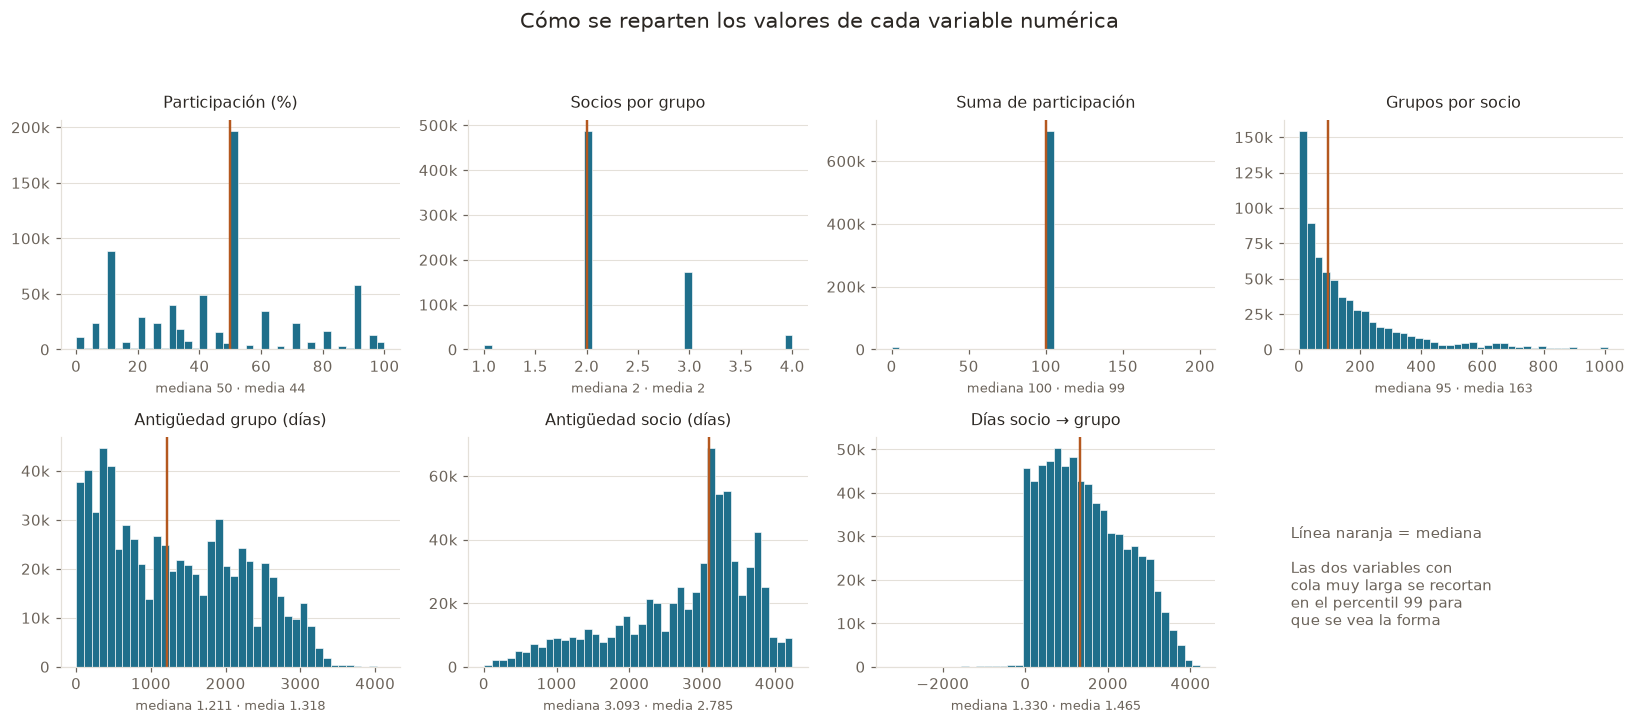

In [13]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Dibuja un histograma por cada variable numérica.
# POR QUÉ    : La tabla de números dice el resumen; el histograma dice la forma. Las dos variables con cola muy larga se recortan en el percentil 99, porque si no, un solo valor extremo aplasta toda la gráfica.
# RESUELVE   : Muestra visualmente cómo se distribuye cada variable.
# ────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 4, figsize=(15, 6.6))
for ax, col in zip(axes.ravel(), NUM):
    s = df[col].dropna()
    s2 = s[s <= s.quantile(.99)] if col in ("n_socios", "n_grupos_del_socio") else s
    ax.hist(s2, bins=40, color=HUE, edgecolor="white", linewidth=.4)
    ax.axvline(s.median(), color=ACC, lw=1.6)
    ax.set_title(ETQ[col], fontsize=10.5, color=INK, pad=8)
    ax.set_xlabel(f"mediana {s.median():,.0f} · media {s.mean():,.0f}".replace(",", "."),
                  fontsize=8.5)
    ax.yaxis.set_major_formatter(lambda v, p: f"{v/1000:.0f}k" if v >= 1000 else f"{v:.0f}")
    limpiar_ejes(ax)
axes.ravel()[-1].axis("off")
axes.ravel()[-1].text(0.02, .62,
    "Línea naranja = mediana\n\nLas dos variables con\ncola muy larga se recortan\nen el percentil 99 para\nque se vea la forma",
    fontsize=9.5, color=INK2, va="top")
fig.suptitle("Cómo se reparten los valores de cada variable numérica",
             fontsize=13.5, color=INK, y=.99)
fig.tight_layout(rect=[0, 0, 1, .95])
plt.show()

### Cómo se lee cada una

**Participación.** La mediana debería dar 50 y la moda también. La explicación es sencilla: la mayoría de grupos son de dos socios repartidos mitad y mitad. En el histograma se ven picos en números redondos —50, 33, 25, 20— porque la gente reparte en fracciones fáciles.

**Socios por grupo.** La asimetría sale enorme, y eso avisa que hay casos raros. La siguiente celda muestra la tabla exacta.

**Suma de participación.** Debería dar 100 siempre. Verificamos.

**Grupos por socio.** Aquí la media y la mediana se separan mucho: la mayoría participa en pocos grupos y unos pocos NITs participan en cientos.

In [14]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Verifica tres cosas concretas sobre los grupos.
# POR QUÉ    : drop_duplicates deja una sola fila por grupo, para no contar el mismo grupo tantas veces como socios tenga. Ese detalle cambia por completo los conteos.
# RESUELVE   : Saca a la luz los grupos de un solo socio y los que no suman 100 %.
# ────────────────────────────────────────────────────────────────────

uno = df.drop_duplicates("Codigo grupo")

print("Cuántos socios tiene cada grupo:")
print(uno["n_socios"].value_counts().sort_index().head(12).to_string())
print(f"\nGrupo con más socios: {uno['n_socios'].max()}")

print("\n¿Los porcentajes suman 100?")
sg = uno["suma_participacion"]
print(f"   Grupos que suman exactamente 100 : {(sg.round(2) == 100).sum():,}".replace(",", "."))
print(f"   Grupos que NO suman 100          : {(sg.round(2) != 100).sum():,}".replace(",", "."))

print(f"\nSocio que aparece en más grupos: {df['n_grupos_del_socio'].max():,}".replace(",", "."))

Cuántos socios tiene cada grupo:
n_socios
1       9139
2     243728
3      57332
4       8029
5       1014
6        177
7         59
8         18
9         12
10         8
11         3
14         1

Grupo con más socios: 44

¿Los porcentajes suman 100?
   Grupos que suman exactamente 100 : 309.442
   Grupos que NO suman 100          : 10.081

Socio que aparece en más grupos: 1.357.0


**Dos cosas que saltan aquí y que vuelven a aparecer en el punto 4:**

- Hay grupos de **un solo socio**. Un consorcio de uno es una contradicción: eso es un error de la base.
- Hay grupos cuya participación **no suma 100 %**. El reparto tiene que cuadrar.

## Punto 3 · Mapa de calor de correlaciones

### Qué es esto

Una **correlación** mide si dos variables se mueven juntas. Va de −1 a 1:

- **Cerca de 1:** cuando una sube, la otra sube.
- **Cerca de −1:** cuando una sube, la otra baja.
- **Cerca de 0:** no tienen relación.

El **mapa de calor** es esa tabla pintada con colores para leerla rápido. Naranja es positiva, azul es negativa, gris es sin relación.

**La advertencia de siempre:** correlación no es causa. Que dos cosas se muevan juntas no significa que una provoque la otra.

findfont: Failed to find font weight 600 for DejaVu Sans, now using 700.


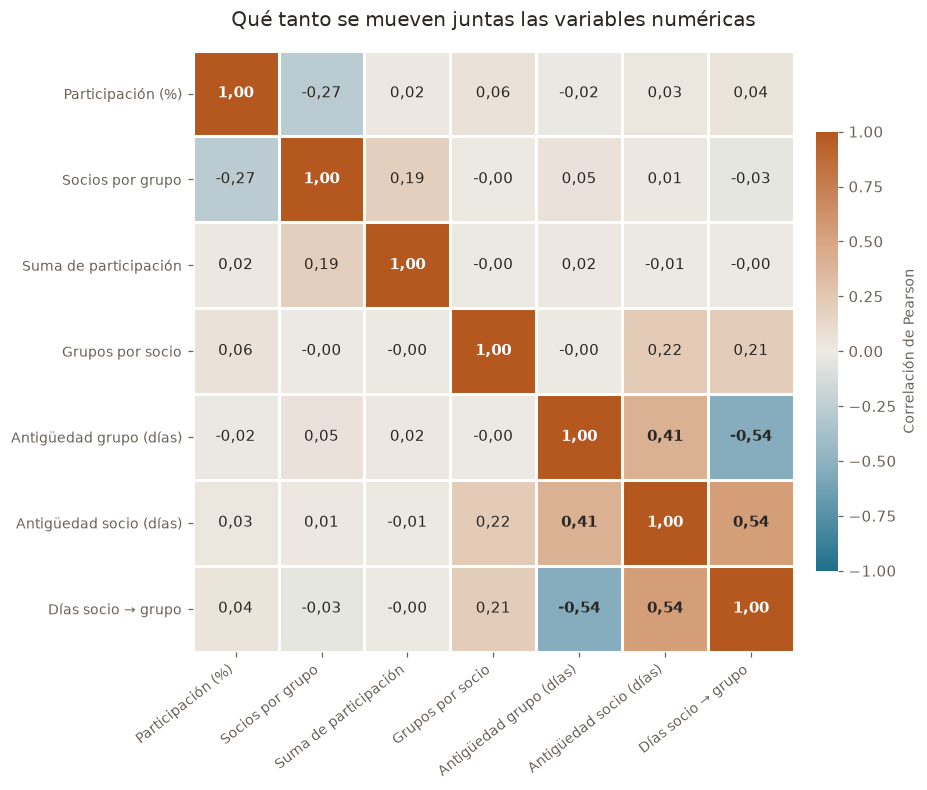


Correlación de Spearman (detecta relaciones curvas):


,participacion_pct,n_socios,suma_participacion,n_grupos_del_socio,antiguedad_grupo_dias,antiguedad_socio_dias,dif_dias_socio_grupo
participacion_pct,1.000,-0.370,0.012,0.047,0.005,0.055,0.036
n_socios,-0.370,1.000,0.231,0.044,0.049,0.002,-0.028
suma_participacion,0.012,0.231,1.000,-0.001,0.019,-0.006,0.002
n_grupos_del_socio,0.047,0.044,-0.001,1.000,-0.012,0.279,0.261
antiguedad_grupo_dias,0.005,0.049,0.019,-0.012,1.000,0.361,-0.506
antiguedad_socio_dias,0.055,0.002,-0.006,0.279,0.361,1.000,0.532
dif_dias_socio_grupo,0.036,-0.028,0.002,0.261,-0.506,0.532,1.000


In [15]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Calcula las correlaciones y las pinta como mapa de calor.
# POR QUÉ    : imshow pinta la matriz como una imagen y el doble bucle escribe el número encima de cada casilla. Se calcula también Spearman porque detecta relaciones que suben o bajan sin ser una línea recta.
# RESUELVE   : Entrega el punto 3 del ejercicio.
# ────────────────────────────────────────────────────────────────────

corr = df[NUM].corr()

fig, ax = plt.subplots(figsize=(8.6, 7.2))
im = ax.imshow(corr.values, cmap=CMAP, vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM))); ax.set_yticks(range(len(NUM)))
ax.set_xticklabels([ETQ[c] for c in NUM], rotation=38, ha="right", fontsize=9)
ax.set_yticklabels([ETQ[c] for c in NUM], fontsize=9)
for i in range(len(NUM)):
    for j in range(len(NUM)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}".replace(".", ","), ha="center", va="center",
                fontsize=9.5, color="white" if abs(v) > .55 else INK,
                fontweight="600" if abs(v) > .3 else "normal")
ax.set_xticks(np.arange(-.5, len(NUM), 1), minor=True)
ax.set_yticks(np.arange(-.5, len(NUM), 1), minor=True)
ax.grid(which="minor", color="white", lw=2); ax.tick_params(which="minor", length=0)
for sp in ax.spines.values(): sp.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=.72, pad=.03)
cb.set_label("Correlación de Pearson", fontsize=9, color=INK2); cb.outline.set_visible(False)
ax.set_title("Qué tanto se mueven juntas las variables numéricas",
             fontsize=13, color=INK, pad=16)
plt.show()

print("\nCorrelación de Spearman (detecta relaciones curvas):")
df[NUM].corr(method="spearman").round(3)

### Qué encontrar aquí

**Socios por grupo ↔ Participación: negativa.** Es sentido común convertido en número: si el 100 % se reparte entre más socios, a cada uno le toca menos. Esta es la relación que exploramos en el punto 5.

**Antigüedad del socio ↔ Días socio→grupo: positiva y fuerte.** Hay que tomarla con cuidado: las dos variables se calculan a partir de la misma fecha, así que en parte están relacionadas **por construcción**, no por un fenómeno real. A eso se le dice **correlación espuria** y es una trampa clásica que conviene declarar.

**Antigüedad del socio ↔ Grupos por socio: positiva y débil.** Entre más años lleva una empresa registrada, en más grupos ha alcanzado a participar. Esta sí tiene explicación de fondo.

**Lo que no hay.** Casi todo lo demás está cerca de cero, y eso también es un hallazgo: las variables de esta tabla son bastante independientes entre sí. Para predecir algo habría que traer datos de otras tablas.

## Punto 4 · Nulos, ceros, faltantes y duplicados

Esta es la parte menos vistosa y la más importante. Calcular promedios sobre datos sucios da un resultado que se ve perfecto y está mal.

### 4.1 Cuánto falta en cada columna

Ya tradujimos los centinelas, así que ahora el conteo sí refleja la realidad.

In [16]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Cuenta cuántos datos faltan en cada columna.
# POR QUÉ    : Se corre después de traducir los centinelas, así que ahora el conteo sí refleja la realidad.
# RESUELVE   : Primera mitad del punto 4.
# ────────────────────────────────────────────────────────────────────

falta = pd.DataFrame({
    "vacíos": df[list(API)].isna().sum(),
    "% vacío": (df[list(API)].isna().mean() * 100).round(2)
}).sort_values("% vacío", ascending=False)
falta

,vacíos,% vacío
Codigo categoría principal grupo,707035,99.90
Descripción código categoría principal grupo,707035,99.90
Departamento grupo,706301,99.80
Sitio web grupo,692972,97.91
Numero fax grupo,674517,95.30
Numero doc representante legal grupo,616296,87.08
NIT Grupo,616296,87.08
Numero teléfono grupo,466559,65.92
Tipo doc representante legal grupo,438097,61.90
Ubicación Participante,240075,33.92


### 4.2 Columnas que sobran

Una columna no sirve por dos razones distintas: porque está casi siempre vacía, o porque todas las filas dicen lo mismo. A lo segundo se le llama **varianza cero**: es como una lista de personas donde la columna «tiene cabeza» dice «sí» en todas.

In [17]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Identifica las columnas que no aportan nada.
# POR QUÉ    : Una columna sobra por dos razones distintas: está casi siempre vacía, o todas las filas dicen lo mismo. Lo segundo se llama varianza cero.
# RESUELVE   : Permite descartar columnas antes de seguir trabajando.
# ────────────────────────────────────────────────────────────────────

print("COLUMNAS QUE SOBRAN\n" + "-" * 60)
for col in API:
    vacio = df[col].isna().mean()
    vc = df[col].value_counts()
    dom = vc.iloc[0] / len(df) if len(vc) else 0
    if vacio > .60:
        print(f"{col:46} vacía el {vacio*100:5.1f} %")
    elif dom > .98:
        print(f"{col:46} el {dom*100:5.1f} % dice siempre {vc.index[0]!r}")

COLUMNAS QUE SOBRAN
------------------------------------------------------------
NIT Grupo                                      vacía el  87.1 %
Es Entidad                                     el 100.0 % dice siempre 'No'
Es proveedor                                   el 100.0 % dice siempre 'No'
Codigo categoría principal grupo               vacía el  99.9 %
Descripción código categoría principal grupo   vacía el  99.9 %
Numero teléfono grupo                          vacía el  65.9 %
Numero fax grupo                               vacía el  95.3 %
Pais grupo                                     el 100.0 % dice siempre 'CO'
Departamento grupo                             vacía el  99.8 %
Sitio web grupo                                vacía el  97.9 %
Tipo doc representante legal grupo             vacía el  61.9 %
Numero doc representante legal grupo           vacía el  87.1 %


### 4.3 Duplicados

Tres pruebas distintas, de la más estricta a la más laxa.

In [18]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Busca filas duplicadas con tres pruebas de distinta exigencia.
# POR QUÉ    : Una fila puede estar repetida de principio a fin, o repetir solo la combinación que debería ser única. Las tres pruebas detectan errores distintos.
# RESUELVE   : Detecta cargues dobles y registros inconsistentes.
# ────────────────────────────────────────────────────────────────────

print(f"Filas idénticas de principio a fin        : {df.duplicated().sum():,}".replace(",", "."))
print(f"Mismo grupo + mismo código de participante: "
      f"{df.duplicated(subset=['Codigo grupo','Codigo participante']).sum():,}".replace(",", "."))
print(f"Mismo grupo + mismo NIT de participante   : "
      f"{df.duplicated(subset=['Codigo grupo','NIT Participante']).sum():,}".replace(",", "."))

Filas idénticas de principio a fin        : 0
Mismo grupo + mismo código de participante: 0
Mismo grupo + mismo NIT de participante   : 77


Los primeros dos deberían dar cero. El tercero puede dar algunos casos: el mismo NIT aparece dos veces en el mismo grupo con códigos distintos. Puede ser una empresa registrada dos veces o un error de digitación.

### 4.4 Valores en cero e imposibles

Aquí buscamos cosas que no pueden pasar en la vida real.

In [19]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Busca valores que no pueden existir en la vida real.
# POR QUÉ    : Un socio con 0 %, un consorcio de una sola empresa o un socio registrado después del grupo al que pertenece son imposibles.
# RESUELVE   : Separa el error de captura del dato legítimo.
# ────────────────────────────────────────────────────────────────────

print("VALORES IMPOSIBLES O SOSPECHOSOS\n" + "-" * 60)
print(f"Participación en 0 %                   : {(df['participacion_pct'] == 0).sum():,}".replace(",", "."))
print(f"Grupos de un solo integrante           : {(uno['n_socios'] == 1).sum():,}".replace(",", "."))
print(f"Grupos cuya participación no suma 100  : "
      f"{(uno['suma_participacion'].round(2) != 100).sum():,}".replace(",", "."))
print(f"Socio registrado DESPUÉS que el grupo  : {(df['dif_dias_socio_grupo'] < 0).sum():,}".replace(",", "."))
print(f"Filas sin datos del socio              : {df['Codigo participante'].isna().sum():,}".replace(",", "."))

VALORES IMPOSIBLES O SOSPECHOSOS
------------------------------------------------------------
Participación en 0 %                   : 263
Grupos de un solo integrante           : 9.139
Grupos cuya participación no suma 100  : 10.081
Socio registrado DESPUÉS que el grupo  : 2.202
Filas sin datos del socio              : 9.114


### 4.5 Cuánto hay que botar

Juntamos todos los problemas y vemos cuánto se pierde. Si se pierde poco, la base está bien cuidada.

In [20]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Junta todos los problemas y mide cuánto habría que botar.
# POR QUÉ    : El símbolo | significa 'o': una fila se descarta si tiene cualquiera de los problemas. Se mide el porcentaje porque esa cifra dice si la base está sana.
# RESUELVE   : Cierra el punto 4 con una conclusión cuantificada.
# ────────────────────────────────────────────────────────────────────

descartar = (df["participacion_pct"].isna()
             | df["Codigo participante"].isna()
             | (df["n_socios"] == 1)
             | (df["suma_participacion"].round(2) != 100)
             | (df["dif_dias_socio_grupo"] < 0))

print(f"Filas a descartar : {descartar.sum():,}".replace(",", "."))
print(f"Porcentaje        : {100*descartar.mean():.2f} %")
print(f"Filas que quedan  : {(~descartar).sum():,}".replace(",", "."))
print(f"Grupos que quedan : {df.loc[~descartar, 'Codigo grupo'].nunique():,}".replace(",", "."))

Filas a descartar : 13.652
Porcentaje        : 1.93 %
Filas que quedan  : 694.098
Grupos que quedan : 309.420


## Punto 5 · Gráfico de dispersión

### 5.1 La regla que hay que respetar

> Un gráfico de dispersión necesita que **las dos variables sean continuas**, o sea que puedan tomar cualquier valor intermedio.

«Número de socios» solo puede ser 1, 2, 3, 4… No existe un grupo de 2,7 socios. Si lo dibujáramos, los puntos se apilarían en columnas verticales y el resultado parecería un código de barras.

Por eso cruzamos dos variables que sí se comportan de forma continua:

- **Eje horizontal:** años que lleva la empresa registrada en la plataforma.
- **Eje vertical:** número de grupos distintos en los que ha participado.

Aquí cada punto es **una empresa socia**, no una fila del archivo.

In [21]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Arma una tabla nueva con una fila por empresa socia.
# POR QUÉ    : Hasta aquí cada fila era un socio dentro de un grupo. Para el scatter necesitamos una fila por empresa, así que se agrupa por NIT y se cuenta en cuántos grupos distintos aparece cada una.
# RESUELVE   : Cambia la unidad de análisis, que es lo que hace posible el gráfico.
# ────────────────────────────────────────────────────────────────────

nit = (df.dropna(subset=["NIT Participante", "f_socio"])
         .groupby("NIT Participante")
         .agg(grupos=("Codigo grupo", "nunique"),
              antiguedad=("antiguedad_socio_dias", "max"))
         .reset_index())
nit["anios"] = nit["antiguedad"] / 365.25

print(f"Empresas socias distintas : {len(nit):,}".replace(",", "."))
print(f"Correlación Pearson       : {nit['antiguedad'].corr(nit['grupos']):.3f}")
print(f"Correlación Spearman      : {nit['antiguedad'].corr(nit['grupos'], method='spearman'):.3f}")

Empresas socias distintas : 39.006
Correlación Pearson       : 0.178
Correlación Spearman      : 0.284


### 5.2 El problema de la escala

El número de grupos por empresa va desde 1 hasta más de mil. En una **escala normal** —la de toda la vida, donde de 0 a 10 hay la misma distancia que de 990 a 1.000— el eje tiene que estirarse tanto para que quepan las empresas gigantes que el 95 % queda aplastado contra el piso.

Por eso dibujamos **dos paneles, los dos en escala normal**: uno con el rango completo y otro con el eje recortado, donde sí se ve la nube.

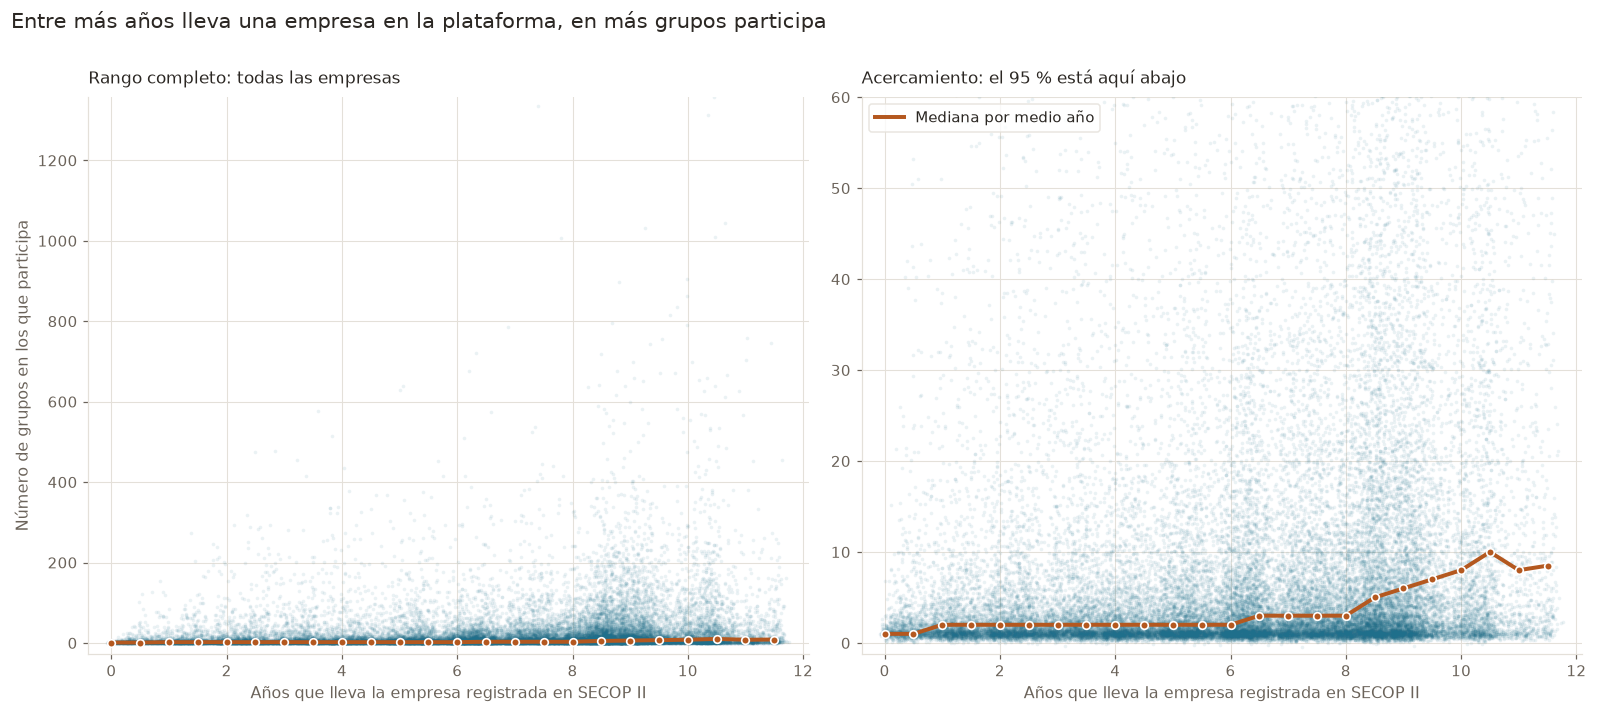


Mediana de grupos según los años en la plataforma:
tramo
0.0      1.0
0.5      1.0
1.0      2.0
1.5      2.0
2.0      2.0
2.5      2.0
3.0      2.0
3.5      2.0
4.0      2.0
4.5      2.0
5.0      2.0
5.5      2.0
6.0      2.0
6.5      3.0
7.0      3.0
7.5      3.0
8.0      3.0
8.5      5.0
9.0      6.0
9.5      7.0
10.0     8.0
10.5    10.0
11.0     8.0
11.5     8.5


In [22]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Dibuja el gráfico de dispersión en dos paneles.
# POR QUÉ    : Se añade un movimiento aleatorio mínimo a los puntos para que no queden encimados, y transparencia para que la densidad se note. Los dos paneles usan escala normal: uno con el rango completo y otro recortado, porque el rango va de 1 a más de mil y en un solo panel la mayoría queda aplastada contra el piso.
# RESUELVE   : Entrega el punto 5 del ejercicio.
# ────────────────────────────────────────────────────────────────────

rng = np.random.default_rng(11)
x = nit["anios"].to_numpy() + rng.normal(0, .06, len(nit))   # movimiento leve
y = nit["grupos"].to_numpy(float) + rng.normal(0, .35, len(nit))

nit["tramo"] = (nit["anios"] * 2).round() / 2
tr = nit.groupby("tramo")["grupos"].agg(["median", "count"])
tr = tr[tr["count"] >= 60]

fig, axes = plt.subplots(1, 2, figsize=(14.6, 6.4))
for ax, lim, tit in [(axes[0], nit["grupos"].max(), "Rango completo: todas las empresas"),
                     (axes[1], 60, "Acercamiento: el 95 % está aquí abajo")]:
    ax.scatter(x, y, s=5.5, alpha=.09, color=HUE, linewidths=0)
    ax.plot(tr.index, tr["median"], "-", color=ACC, lw=2.6, zorder=5, label="Mediana por medio año")
    ax.plot(tr.index, tr["median"], "o", color=ACC, ms=5, mec="white", mew=1.1, zorder=6)
    ax.set_xlim(-.4, 12.1); ax.set_ylim(-lim*.02, lim)
    ax.set_xlabel("Años que lleva la empresa registrada en SECOP II", fontsize=10.5)
    limpiar_ejes(ax, eje_y=False)
    ax.set_title(tit, fontsize=11, color=INK, pad=9, loc="left")
axes[0].set_ylabel("Número de grupos en los que participa", fontsize=10.5)
axes[1].legend(frameon=True, facecolor="white", edgecolor=GRID, fontsize=9.5, loc="upper left")
fig.suptitle("Entre más años lleva una empresa en la plataforma, en más grupos participa",
             fontsize=13.5, color=INK, x=.008, ha="left", y=1.005)
fig.tight_layout()
plt.show()

print("\nMediana de grupos según los años en la plataforma:")
print(tr["median"].to_string())

### 5.3 Qué se ve

**Es una nube de verdad**, y tiene forma: se ensancha hacia arriba a medida que avanza hacia la derecha.

**La línea naranja sube de forma sostenida.** Una empresa que lleva diez años se asocia unas diez veces más que una que acaba de entrar. Tiene sentido: asociarse requiere conocidos, y los conocidos se acumulan con el tiempo.

**La parte de arriba de la nube se dispara después del año 8.** Ahí aparecen las empresas que participan en cientos de grupos. Son pocas pero muy visibles, y son exactamente las que habría que mirar de cerca en un estudio de competencia.

**Advertencia honesta:** la relación existe pero es moderada. La antigüedad explica una parte de cuántos grupos arma una empresa, y queda mucho sin explicar.

### 5.4 El reparto entre socios, en el gráfico correcto

La relación que descartamos para el scatter sigue siendo interesante, así que la dibujamos como corresponde: un **diagrama de cajas**, que es la herramienta para cruzar una variable de valores enteros contra una continua.

**Cómo se lee una caja:** la línea naranja del medio es la mediana. La caja contiene la mitad central de los casos. Las líneas verticales muestran hasta dónde llegan los valores normales.

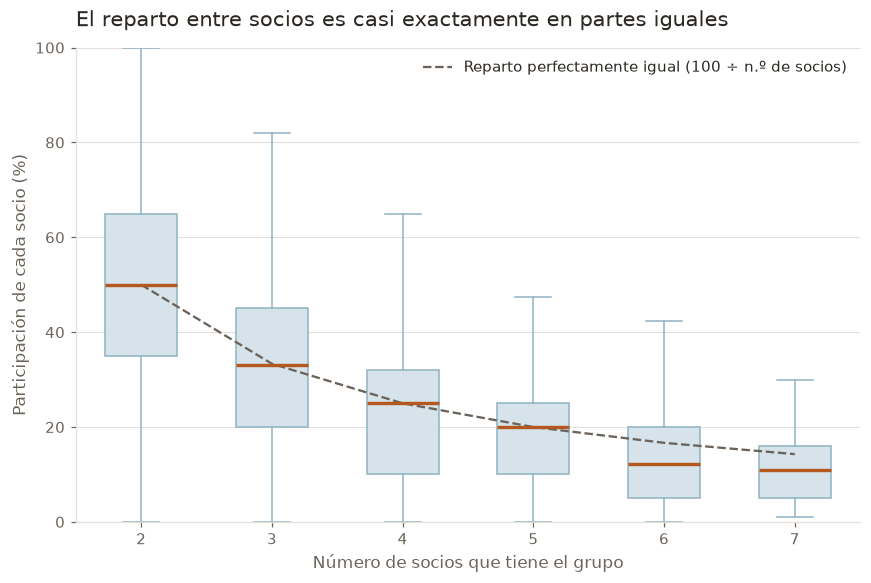

Participación mediana según el número de socios:
n_socios
2    50.0
3    33.0
4    25.0
5    20.0
6    12.2
7    11.0


In [23]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Dibuja el diagrama de cajas del reparto entre socios.
# POR QUÉ    : El número de socios solo toma valores enteros, y para esa clase de variable el gráfico correcto es una caja, no una nube de puntos. La línea punteada marca cómo se vería un reparto perfectamente igual.
# RESUELVE   : Muestra la relación que el scatter no podía representar bien.
# ────────────────────────────────────────────────────────────────────

sub = df.dropna(subset=["participacion_pct", "n_socios"])
sub = sub[(sub["n_socios"] >= 2) & (sub["n_socios"] <= 7)]
datos = [sub.loc[sub["n_socios"] == k, "participacion_pct"].values for k in range(2, 8)]

fig, ax = plt.subplots(figsize=(9.2, 5.6))
ax.boxplot(datos, patch_artist=True, widths=.55, showfliers=False,
           medianprops=dict(color=ACC, lw=2.2),
           boxprops=dict(facecolor="#D6E3EA", edgecolor="#8FB3C2", lw=1),
           whiskerprops=dict(color="#8FB3C2", lw=1),
           capprops=dict(color="#8FB3C2", lw=1))
ax.plot(np.arange(1, 7), [100/k for k in range(2, 8)], "--", color=INK2, lw=1.5,
        label="Reparto perfectamente igual (100 ÷ n.º de socios)")
ax.set_xticks(np.arange(1, 7)); ax.set_xticklabels([str(k) for k in range(2, 8)])
ax.set_xlabel("Número de socios que tiene el grupo", fontsize=11)
ax.set_ylabel("Participación de cada socio (%)", fontsize=11)
ax.set_ylim(0, 100); limpiar_ejes(ax)
ax.legend(frameon=False, fontsize=9.5, loc="upper right")
ax.set_title("El reparto entre socios es casi exactamente en partes iguales",
             fontsize=13.5, color=INK, pad=14, loc="left")
plt.show()

print("Participación mediana según el número de socios:")
print(sub.groupby("n_socios")["participacion_pct"].median().round(1).to_string())

**En Colombia los consorcios se reparten en partes iguales casi siempre.** Las medianas caen casi exactamente sobre la línea punteada.

**La regla se rompe a partir de 6 socios:** ahí la mediana cae por debajo, lo que significa que aparece un socio principal con una tajada grande y varios socios pequeños. En grupos grandes suele haber una empresa que lidera y otras que aportan un requisito puntual.

**Las cajas también cuentan algo.** La caja de 2 socios es altísima: aunque la mitad exacta es lo más común, hay muchas parejas desiguales. A medida que crece el número de socios las cajas se achican, o sea que los grupos grandes reparten de forma más predecible.

## Punto 6 · Llaves para conectar con otras tablas

Una **llave** es una columna que identifica algo de forma única y permite pegar dos tablas distintas, igual que un BUSCARV en Excel pero con tablas enormes.

In [24]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Evalúa qué columnas sirven como llave.
# POR QUÉ    : Una llave debe ser única y no tener vacíos. La última prueba verifica si la pareja grupo + participante identifica cada fila sin repetirse.
# RESUELVE   : Entrega el punto 6 del ejercicio.
# ────────────────────────────────────────────────────────────────────

print("CANDIDATAS A LLAVE\n" + "-" * 60)
for col in ["Codigo grupo", "NIT Grupo", "Codigo participante", "NIT Participante",
            "Ubicación Grupo", "Ubicación Participante"]:
    print(f"{col:24} únicos={df[col].nunique():8,}  vacíos={df[col].isna().sum():8,}"
          .replace(",", "."))

print("\n¿La pareja grupo + participante identifica cada fila sin repetirse?")
dup = df.duplicated(subset=["Codigo grupo", "Codigo participante"]).sum()
print(f"   repeticiones: {dup}  ->  " + ("SÍ, es llave primaria" if dup == 0 else "NO"))

CANDIDATAS A LLAVE
------------------------------------------------------------
Codigo grupo             únicos= 319.523  vacíos=       0
NIT Grupo                únicos=  32.036  vacíos= 616.296
Codigo participante      únicos=  39.596  vacíos=   9.114
NIT Participante         únicos=  39.006  vacíos=   9.269
Ubicación Grupo          únicos=     681  vacíos= 186.853
Ubicación Participante   únicos=     805  vacíos= 240.075

¿La pareja grupo + participante identifica cada fila sin repetirse?
   repeticiones: 0  ->  SÍ, es llave primaria


### Con qué otras tablas se puede unir

Esta base sola cuenta poco. Lo valioso aparece al cruzarla con las otras tablas del SECOP II, que usan los mismos identificadores:

| Para responder… | Se une con | Por la columna |
|---|---|---|
| ¿Qué ofertas presentó este socio? | SECOPII — Ofertas Por Proceso (`wi7w-2nvm`) | `NIT Participante` ↔ `nit_del_proveedor` |
| ¿Qué contratos ganó? | SECOP II — Contratos Electrónicos (`jbjy-vk9h`) | `NIT Participante` ↔ `documento_proveedor` |
| ¿Cuándo se registró y de qué tamaño es? | SECOP II — Proveedores Registrados (`qmzu-gj57`) | `NIT Participante` ↔ `nit` |
| ¿Qué modificaciones tuvieron sus contratos? | SECOP II — Adiciones (`cb9c-h8sn`) | vía el `id_contrato` de la tabla de contratos |

**La llave estrella es `NIT Participante`.** Es la única columna que existe también en las demás tablas del ecosistema y que permite seguirle el rastro a una empresa desde que se registra, pasando por los grupos que arma, hasta los contratos que gana.

## Cierre · Lo que nos llevamos

**Cinco cosas que no se veían al abrir el archivo:**

1. Una fila no es un grupo: es un socio dentro de un grupo. Confundir eso arruina cualquier conteo.
2. La base es de texto casi por completo. Para analizarla numéricamente hubo que fabricar variables.
3. Los vacíos vienen disfrazados de texto y hay que traducirlos antes de medir nada.
4. Hay miles de números escritos con coma decimal que el programa descarta en silencio.
5. Los consorcios colombianos se reparten en partes iguales, y una empresa se asocia más entre más años lleva registrada.

**Tres cosas que se podrían hacer después:**

- Cruzar el NIT con la tabla de ofertas, para ver si los grupos ganan más que las empresas solas.
- Armar un grafo de qué empresas se asocian repetidamente entre sí, que es la base de cualquier estudio de competencia.
- Completar el departamento a partir del municipio, para poder hacer mapas.

**Dos lecciones sobre el oficio:**

- El 80 % del tiempo se va entendiendo qué significa una fila y limpiando textos. El 20 % restante es hacer las gráficas. La parte aburrida es la que sostiene todo lo demás.
- Un gráfico que se ve raro casi siempre está avisando algo: que el tipo de gráfico no corresponde al tipo de variable, o que la escala del eje está distorsionando la lectura.

---

**Fuente:** [Grupos de Proveedores - SECOP II (`ceth-n4bn`) · datos.gov.co](https://www.datos.gov.co/d/ceth-n4bn) — Agencia Nacional de Contratación Pública, Colombia Compra Eficiente. Licencia Creative Commons Attribution Share-Alike 4.0.

---

# Punto 7 · ¿Esta base entra en el análisis global?

Hasta aquí describimos la base. Ahora toca la decisión que de verdad importa: **si esta tabla merece un lugar en el proyecto o si es mejor dejarla afuera.**

La respuesta depende de para quién estemos trabajando. Una misma base puede ser imprescindible para un actor y perfectamente prescindible para otro.

### Los tres actores posibles

| | Quién es | Qué decisión toma |
|---|---|---|
| **A · Contraloría** | Órgano de control fiscal, veeduría, prensa investigativa | Qué procesos audita primero, con recursos limitados |
| **B · Entidad compradora** | La alcaldía, ministerio o empresa estatal que lanza el proceso | Cómo diseña el pliego y a quién invita |
| **C · Empresa proveedora** | La empresa que quiere ganarse el contrato | A qué proceso se presenta, con qué precio y con qué aliados |

### Los cinco criterios con los que vamos a juzgarla

No basta con decir «sirve» o «no sirve». Estos son los filtros:

1. **Pertinencia** — ¿responde una pregunta que ese actor realmente se hace?
2. **Unidad de análisis** — ¿lo que hay en las filas coincide con lo que ese actor decide?
3. **Autosuficiencia** — ¿sirve sola, o solo tiene valor cruzada con otras tablas?
4. **Validabilidad** — ¿ese actor puede comprobar si el resultado le sirvió?
5. **Costo de limpieza** — ¿cuánto trabajo cuesta dejarla usable?

Primero medimos las evidencias, después decidimos.

In [25]:
# ────────────────────────────────────────────────────────────────────
# QUÉ HACE   : Calcula las evidencias que sustentan la decisión final.
# POR QUÉ    : Antes de opinar sobre si la base sirve, hay que medir. Se revisa la capacidad de cruce, lo que la tabla no tiene, la concentración del mercado y las parejas de empresas que se repiten.
# RESUELVE   : Convierte la decisión del punto 7 en un argumento con números.
# ────────────────────────────────────────────────────────────────────

print("EVIDENCIAS PARA LA DECISIÓN")
print("=" * 62)

# 1) ¿Qué tanto se puede cruzar con otras tablas?
nit_ok = df["NIT Participante"].notna().mean()
print(f"\n1. CAPACIDAD DE CRUCE")
print(f"   Filas con NIT de socio utilizable : {nit_ok*100:5.1f} %")
print(f"   NITs distintos                    : {df['NIT Participante'].nunique():,}".replace(",", "."))

# 2) ¿Qué NO tiene esta tabla?
faltantes = ["entidad compradora", "proceso de contratación", "valor del contrato",
             "resultado (ganó / no ganó)", "sector o categoría utilizable"]
print(f"\n2. LO QUE ESTA TABLA NO TIENE")
for f in faltantes:
    print(f"   · {f}")

# 3) Concentración: ¿hay socios que están en todas partes?
hiper = df.loc[df["n_grupos_del_socio"] > 200, "NIT Participante"].nunique()
grupos_con_hiper = df.loc[df["n_grupos_del_socio"] > 200, "Codigo grupo"].nunique()
print(f"\n3. CONCENTRACIÓN DEL MERCADO")
print(f"   Socios presentes en más de 200 grupos : {hiper:,}".replace(",", "."))
print(f"   Grupos que incluyen a uno de ellos    : {grupos_con_hiper:,}".replace(",", "."))
print(f"   Porcentaje de todos los grupos        : "
      f"{100*grupos_con_hiper/df['Codigo grupo'].nunique():.1f} %")

# 4) Parejas que se repiten: la evidencia clave para un auditor
duos = df[df["n_socios"] == 2].dropna(subset=["NIT Participante"])
pares = (duos.groupby("Codigo grupo")["NIT Participante"]
              .apply(lambda s: tuple(sorted(s.astype(str)))))
pares = pares[pares.map(len) == 2]
conteo = pares.value_counts()
print(f"\n4. PAREJAS QUE SE REPITEN (solo grupos de 2 socios)")
print(f"   Parejas distintas                  : {len(conteo):,}".replace(",", "."))
print(f"   Parejas que se repiten 5+ veces    : {(conteo >= 5).sum():,}".replace(",", "."))
print(f"   Parejas que se repiten 20+ veces   : {(conteo >= 20).sum():,}".replace(",", "."))
print(f"   La pareja más frecuente aparece en : {conteo.max()} grupos")

EVIDENCIAS PARA LA DECISIÓN

1. CAPACIDAD DE CRUCE
   Filas con NIT de socio utilizable :  98.7 %
   NITs distintos                    : 39.006

2. LO QUE ESTA TABLA NO TIENE
   · entidad compradora
   · proceso de contratación
   · valor del contrato
   · resultado (ganó / no ganó)
   · sector o categoría utilizable

3. CONCENTRACIÓN DEL MERCADO
   Socios presentes en más de 200 grupos : 563
   Grupos que incluyen a uno de ellos    : 126.724
   Porcentaje de todos los grupos        : 39.7 %

4. PAREJAS QUE SE REPITEN (solo grupos de 2 socios)
   Parejas distintas                  : 70.872
   Parejas que se repiten 5+ veces    : 9.687
   Parejas que se repiten 20+ veces   : 1.747
   La pareja más frecuente aparece en : 979 grupos


### Lectura de las evidencias

**La cifra 4 es la más importante de todo el cuaderno para efectos de decisión.** Que existan parejas de empresas que se asocian decenas de veces significa que esta base permite **reconstruir la red de alianzas del mercado**. Ninguna otra tabla del SECOP II permite eso.

Las cifras 2 y 3 marcan el límite: la tabla no dice quién compra, ni cuánto vale el contrato, ni quién ganó.

---

## 7.1 · Actor A · Contraloría y control fiscal

| Criterio | Evaluación |
|---|---|
| **Pertinencia** | **Alta.** La pregunta «¿qué empresas se asocian sistemáticamente entre sí?» es exactamente el punto de partida de una investigación por acuerdos entre competidores |
| **Unidad de análisis** | **Media.** El auditor decide sobre procesos, no sobre grupos. Hay que agregar por par de empresas y después bajar a procesos |
| **Autosuficiencia** | **Baja.** Sola muestra quién se asocia, sin decir si ganaron ni cuánta plata movieron. Necesita el cruce con contratos |
| **Validabilidad** | **Baja.** Confirmar si una alianza repetida es un cartel exige una investigación formal, no un dato |
| **Costo de limpieza** | **Bajo.** Se descarta menos del 2 % |

### Lo que le aporta

- **Detección de alianzas recurrentes.** Empresas que aparecen juntas una y otra vez son una señal de partida legítima.
- **Mapa de socios hiperactivos.** Las empresas presentes en cientos de grupos concentran una parte grande del mercado.
- **Rastreo de estructuras repetidas.** El mismo representante legal en muchos grupos distintos es una alerta barata de calcular.

### Lo que le falta

- No dice **si el grupo ganó algo**. Una alianza que nunca gana no es un problema.
- No dice **cuánta plata** hay detrás.
- No permite **priorizar**, que es lo que el auditor necesita: sin valor ni resultado, no hay forma de ordenar por riesgo.

### Veredicto para el actor A

> **Entra, pero como tabla de apoyo.** Aporta una dimensión que ninguna otra tabla tiene —la red de alianzas—, y esa dimensión es difícil de conseguir por otro lado. Sola no sostiene un análisis de riesgo; cruzada con contratos, es la pieza que convierte «este proveedor es sospechoso» en «este grupo de proveedores opera junto».

---

## 7.2 · Actor B · Entidad pública que lanza el proceso

| Criterio | Evaluación |
|---|---|
| **Pertinencia** | **Baja.** La entidad se pregunta cómo atraer más oferentes y cómo diseñar mejores pliegos. Esta tabla no habla de pliegos |
| **Unidad de análisis** | **Baja.** La entidad decide sobre sus procesos. Aquí no existe la columna de entidad compradora |
| **Autosuficiencia** | **Muy baja.** Sin cruzar, una entidad no puede ni siquiera filtrar sus propios casos |
| **Validabilidad** | **Media.** Podría medir si sus procesos atraen consorcios, pero solo después de dos cruces |
| **Costo de limpieza** | **Bajo**, aunque irrelevante si la tabla no responde su pregunta |

### El problema de fondo

**Esta tabla no tiene ninguna columna que identifique a la entidad compradora ni al proceso.** Para que una alcaldía pueda preguntarse «¿cuántos de los que me ofertan son consorcios?», tendría que:

1. Sacar sus procesos de la tabla de procesos,
2. Sacar los oferentes de la tabla de ofertas,
3. Y recién ahí cruzar con esta tabla por NIT.

Tres saltos para una pregunta que la tabla de ofertas responde en uno.

### Lo poco que sí le aporta

- Saber si un proponente concreto es un consorcio y quiénes lo componen, cuando ya lo tiene enfrente.
- Verificar si un socio del consorcio está simultáneamente en otro grupo que compite por el mismo proceso, que sería una irregularidad. Este uso puntual sí es valioso.

### Veredicto para el actor B

> **No entra como fuente principal. Entra como tabla de consulta puntual.** Si el proyecto se enfoca en la entidad compradora, esta base ocupa esfuerzo de limpieza y cruce sin aportar a la decisión central. La excepción es el control de socios duplicados entre consorcios competidores, que es un uso concreto y defendible.

---

## 7.3 · Actor C · Empresa que quiere ganar el contrato

| Criterio | Evaluación |
|---|---|
| **Pertinencia** | **Alta.** «¿Con quién me alío para cumplir requisitos que solo no cumplo?» es una decisión comercial real y frecuente |
| **Unidad de análisis** | **Alta.** La empresa decide sobre socios, y aquí cada fila es un socio |
| **Autosuficiencia** | **Media.** Sirve sola para prospección de aliados; necesita cruce para saber si esas alianzas ganan |
| **Validabilidad** | **Alta.** La empresa sabe perfectamente si la alianza que armó le sirvió |
| **Costo de limpieza** | **Bajo** |

### Lo que le aporta

- **Prospección de aliados.** Qué empresas de su sector tienen experiencia armando consorcios y con quién los arman.
- **Inteligencia sobre competidores.** Con quién se está aliando la empresa que siempre le gana.
- **Referencia de reparto.** El punto 5 mostró que el estándar del mercado es partes iguales. Eso sirve para negociar el porcentaje.
- **Detección de socios hiperactivos.** Empresas que arman consorcios con todo el mundo son candidatas naturales a socio, con la advertencia de que también pueden estar sobrecomprometidas.

### Lo que le falta

- No dice **qué alianzas ganan**. La tabla registra que se formaron, no que tuvieron éxito.
- No dice **en qué sector** compite cada grupo, porque la columna de categoría está vacía en el 99,9 % de los casos. Esa ausencia obliga a inferir el sector desde otra tabla.

### Veredicto para el actor C

> **Entra, y con un rol propio.** Es la única fuente que permite responder «con quién me alío». Además tiene una ventaja rara: la empresa puede validar el resultado con su propia experiencia, sin depender de nadie.

---

## 7.4 · Decisión

| | **A · Contraloría** | **B · Entidad compradora** | **C · Empresa proveedora** |
|---|---|---|---|
| Pertinencia | Alta | Baja | Alta |
| Unidad de análisis | Media | Baja | Alta |
| Autosuficiencia | Baja | Muy baja | Media |
| Validabilidad | Baja | Media | Alta |
| Costo de limpieza | Bajo | Bajo | Bajo |
| **Decisión** | **Entra como apoyo** | **No entra como fuente principal** | **Entra con rol propio** |

### Recomendación

**Si el proyecto se enfoca en la empresa proveedora o en el control fiscal, esta base entra.** En el primer caso responde una pregunta que ninguna otra tabla responde; en el segundo aporta la dimensión de red que es imposible de reconstruir desde otro lado.

**Si el proyecto se enfoca en la entidad compradora, esta base se deja por fuera del núcleo** y se reserva para una verificación puntual: que un mismo socio no esté en dos consorcios que compiten por el mismo proceso.

### La condición que hay que cumplir en cualquier caso

Esta tabla **no se sostiene sola**. Entre sin el cruce con `jbjy-vk9h` (Contratos Electrónicos) o con `wi7w-2nvm` (Ofertas), y lo único que se podrá decir es cuántos consorcios existen y cómo reparten. Eso es una descripción, no un análisis.

**El plan mínimo de integración, en orden:**

1. Cruzar por `NIT Participante` con la tabla de ofertas, para saber qué grupos efectivamente se presentaron.
2. Cruzar con contratos, para saber cuáles ganaron y por cuánta plata.
3. Construir el grafo de coocurrencia de socios, que es el producto final y el que justifica haber traído esta base al proyecto.

### Lo que hay que decir en la sustentación

Que esta base **aporta una dimensión estructural que las demás tablas no tienen** —quién trabaja con quién—, y que su debilidad es la contracara de esa virtud: describe relaciones, sin describir resultados. El valor aparece cuando se le pega el resultado desde otra tabla.